# Phase 2 — Candidate Regression Model Comparison

Implements Chapter 3, Section 3.3 and Chapter 4, Section 4.4 of the dissertation
*"Dynamic Feature Selection for Non-Stationary Environments"*.

Compares Linear Regression, Random Forest, and XGBoost on the fixed, twelve-feature
candidate set produced by Phase 1, using the same temporally ordered train/test split.
This is the one genuinely independent comparison in the methodology (Chapter 3, Table 3.4,
Stage 1) -- model choice here does not depend on any drift-detector or feature-selection
decision made later.

**Output:**
- `results/tables/phase2_model_comparison.csv` — predictive-accuracy metrics per model
- `results/figures/phase2_model_comparison.png` — all five predictive-accuracy metrics, per model
- `results/figures/phase2_runtime_comparison.png` — fit/predict runtime per model
- `results/models/*.joblib` — the three fitted models, for reuse in later phases
- `results/tables/phase2_artifacts.json` — best/second-best model identity, consumed by Phases 3–9

In [1]:
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/dissertation-project'
except ImportError:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

sys.path.append(os.path.join(PROJECT_ROOT, 'src'))
print('Project root:', PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/dissertation-project


In [2]:
!pip install scikit-learn==1.8.0 statsmodels xgboost river --quiet

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

import data_utils as du
import models as mdl
import metrics as mt

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)

## 1. Load the processed train/test split produced by Phase 1

In [4]:
train_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data/processed/smart_grid_train.csv'))
test_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data/processed/smart_grid_test.csv'))

feature_cols = du.CANDIDATE_FEATURES
target_col = du.TARGET_COL

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

print(f'Train: {X_train.shape[0]} rows, {X_train.shape[1]} features')
print(f'Test:  {X_test.shape[0]} rows, {X_test.shape[1]} features')
print()
print('Candidate features:', feature_cols)

Train: 40000 rows, 12 features
Test:  10000 rows, 12 features

Candidate features: ['Voltage (V)', 'Reactive Power (kVAR)', 'Power Factor', 'Solar Power (kW)', 'Wind Power (kW)', 'Grid Supply (kW)', 'Voltage Fluctuation (%)', 'Overload Condition', 'Transformer Fault', 'Temperature (°C)', 'Humidity (%)', 'Electricity Price (USD/kWh)']


## 2. Train and evaluate all three candidate models

Uses `models.compare_models()`, which fits each model with a fixed random seed, predicts on the held-out (chronologically later) test set, and computes the full predictive-accuracy metric suite from `metrics.py`: MAE, RMSE, R², Adjusted R², and MAPE.

In [5]:
results_df, fitted_models = mdl.compare_models(X_train, y_train, X_test, y_test)
results_df

,model,display_name,MAE,RMSE,R2,MAPE,Adjusted_R2,fit_runtime_s,predict_runtime_s
0,random_forest,Random Forest,1.417570,1.761192,0.654728,28.047321,0.654313,53.951813,0.222185
1,xgboost,XGBoost,1.419191,1.766726,0.652555,28.192792,0.652137,1.606712,0.060424
2,linear_regression,Linear Regression,1.557034,1.904087,0.596427,33.816179,0.595942,0.098390,0.005664


## 3. Visualise the comparison — all five predictive-accuracy metrics

One panel per metric (Chapter 3, Table 3.5), rather than MAE/R² alone, so the full picture is visible at a glance: MAE, RMSE, and MAPE are "lower is better"; R² and Adjusted R² are "higher is better" (shared y-axis limits so the two aren't visually conflated with the error metrics).

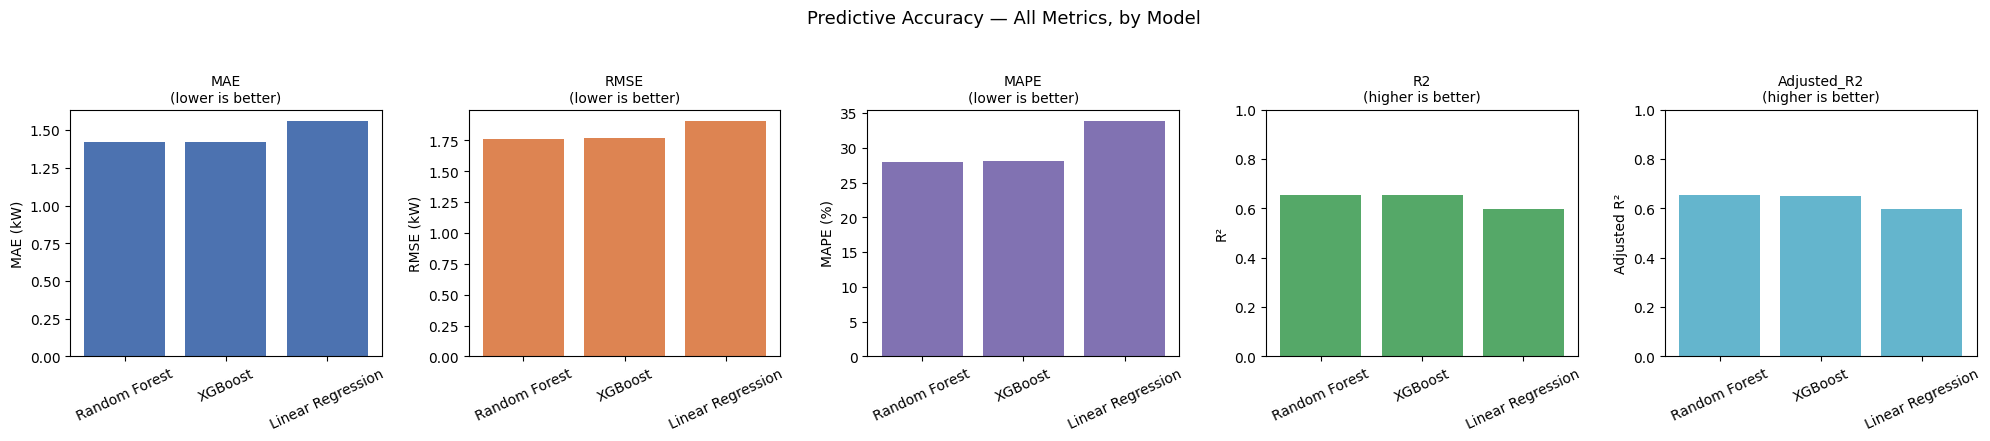

Saved figure to /content/drive/MyDrive/dissertation-project/results/figures/phase2_model_comparison.png


In [6]:
metric_specs = [
    ('MAE', 'MAE (kW)', '#4C72B0', 'lower is better'),
    ('RMSE', 'RMSE (kW)', '#DD8452', 'lower is better'),
    ('MAPE', 'MAPE (%)', '#8172B2', 'lower is better'),
    ('R2', 'R²', '#55A868', 'higher is better'),
    ('Adjusted_R2', 'Adjusted R²', '#64B5CD', 'higher is better'),
]

fig, axes = plt.subplots(1, 5, figsize=(20, 4.2))

for ax, (col, ylabel, color, direction) in zip(axes, metric_specs):
    ax.bar(results_df['display_name'], results_df[col], color=color)
    ax.set_ylabel(ylabel)
    ax.set_title(f'{col}\n({direction})', fontsize=10)
    ax.tick_params(axis='x', rotation=25)
    if col in ('R2', 'Adjusted_R2'):
        ax.set_ylim(0, 1.0)

fig.suptitle('Predictive Accuracy — All Metrics, by Model', y=1.04, fontsize=13)
plt.tight_layout()

fig_path = os.path.join(PROJECT_ROOT, 'results/figures/phase2_model_comparison.png')
os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print('Saved figure to', fig_path)

### Visualisation: computational cost

Predictive accuracy alone does not determine practical deployability (Chapter 3, Section 3.10) — fit and predict runtime are reported here, on a log scale, since Random Forest's fit time is roughly two orders of magnitude larger than the others.

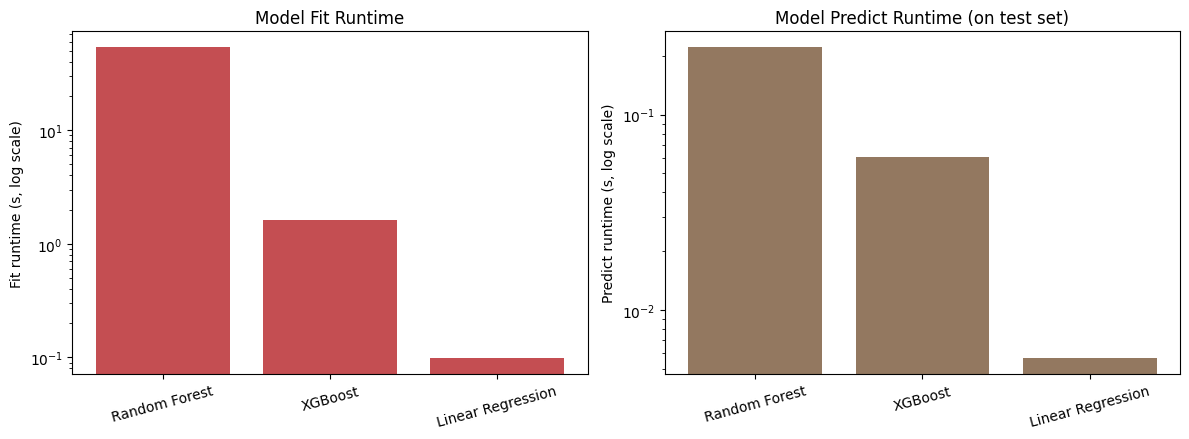

Saved figure to /content/drive/MyDrive/dissertation-project/results/figures/phase2_runtime_comparison.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(results_df['display_name'], results_df['fit_runtime_s'], color='#C44E52')
axes[0].set_ylabel('Fit runtime (s, log scale)')
axes[0].set_yscale('log')
axes[0].set_title('Model Fit Runtime')
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar(results_df['display_name'], results_df['predict_runtime_s'], color='#937860')
axes[1].set_ylabel('Predict runtime (s, log scale)')
axes[1].set_yscale('log')
axes[1].set_title('Model Predict Runtime (on test set)')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
runtime_fig_path = os.path.join(PROJECT_ROOT, 'results/figures/phase2_runtime_comparison.png')
plt.savefig(runtime_fig_path, dpi=150)
plt.show()
print('Saved figure to', runtime_fig_path)

## 4. Identify the best and second-best models

Ranked by MAE, consistent with Chapter 3 (Section 3.3). The best model is carried forward as the primary model for Phases 3–7; the second-best is used in the combination-validation check (Phase 6); and the non-best model (whichever of Random Forest / a non-RF model is not selected as best) is reserved for the Random Forest importance bias check in Phase 5 (Chapter 3, Section 3.6.1).

In [8]:
ranking = mdl.rank_models(results_df, by='MAE')
best_model_name = ranking[0]
second_best_model_name = ranking[1]

# For the Section 3.6.1 bias check: the best non-Random-Forest model, so RF-importance
# selected features can be re-scored downstream with a model that isn't RF itself.
non_rf_candidates = [m for m in ranking if m != 'random_forest']
non_rf_model_name = non_rf_candidates[0]

print('Ranking (best to worst, by MAE):', ranking)
print('Best model:            ', mdl.MODEL_DISPLAY_NAMES[best_model_name])
print('Second-best model:     ', mdl.MODEL_DISPLAY_NAMES[second_best_model_name])
print('Non-RF model (for 3.6.1):', mdl.MODEL_DISPLAY_NAMES[non_rf_model_name])

Ranking (best to worst, by MAE): ['random_forest', 'xgboost', 'linear_regression']
Best model:             Random Forest
Second-best model:      XGBoost
Non-RF model (for 3.6.1): XGBoost


## 5. Persist artefacts for later phases

In [9]:
# Save the three fitted models
models_dir = os.path.join(PROJECT_ROOT, 'results/models')
for name, model in fitted_models.items():
    mdl.save_model(model, os.path.join(models_dir, f'{name}.joblib'))

# Save the comparison table
table_path = os.path.join(PROJECT_ROOT, 'results/tables/phase2_model_comparison.csv')
results_df.to_csv(table_path, index=False)

# Save the small artefacts every later phase reads
artifacts = {
    'ranking': ranking,
    'best_model': best_model_name,
    'second_best_model': second_best_model_name,
    'non_rf_model_for_bias_check': non_rf_model_name,
    'feature_cols': feature_cols,
    'target_col': target_col,
}
artifacts_path = os.path.join(PROJECT_ROOT, 'results/tables/phase2_artifacts.json')
mdl.save_artifacts(artifacts, artifacts_path)

print('Saved fitted models to', models_dir)
print('Saved comparison table to', table_path)
print('Saved artefacts to', artifacts_path)
print()
print(artifacts)

Saved fitted models to /content/drive/MyDrive/dissertation-project/results/models
Saved comparison table to /content/drive/MyDrive/dissertation-project/results/tables/phase2_model_comparison.csv
Saved artefacts to /content/drive/MyDrive/dissertation-project/results/tables/phase2_artifacts.json

{'ranking': ['random_forest', 'xgboost', 'linear_regression'], 'best_model': 'random_forest', 'second_best_model': 'xgboost', 'non_rf_model_for_bias_check': 'xgboost', 'feature_cols': ['Voltage (V)', 'Reactive Power (kVAR)', 'Power Factor', 'Solar Power (kW)', 'Wind Power (kW)', 'Grid Supply (kW)', 'Voltage Fluctuation (%)', 'Overload Condition', 'Transformer Fault', 'Temperature (°C)', 'Humidity (%)', 'Electricity Price (USD/kWh)'], 'target_col': 'Predicted Load (kW)'}


## Summary

This notebook implements Chapter 3, Section 3.3 (Stage 1 of the sequential component selection, Table 3.4) and Chapter 4, Section 4.4. The best-performing model, identified purely by predictive accuracy on the held-out chronological test set, is carried forward as the fixed model used throughout Phases 3–7 (the window-length sensitivity analysis, drift detector comparison, and feature-selection comparison), consistent with the sequential, dependency-aware design established in Chapter 3.